# Figure 3 | Monthly weather at the Juneau modeling sites

A publication revision of [the in-review figure](inreview/figure3.ipynb).
The three columns retain the manuscript's site-specific water years. Rows compare
HRRR-AK forcing with station observations for air temperature, relative humidity,
and precipitation. Run with the manuscript's rasterio environment.

In [9]:
from calendar import month_abbr
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import xarray as xr

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'envs/rasterio.yml').is_file() and (p / 'figures').is_dir())
output_dir = root / 'figures/files'
met = Path('/hdd/snow_hydrology/met_station')
hrrr = Path('/hdd/snow_hydrology/hrrrak/icefield_domain/netcdf')

# Observation file and first and last water year.
sites = {
    'PPSA': ('ppsa2/pppsa_met_station_data_synoptic_2026-03-20', 2023, 2025),
    'TRAM': ('tram/tram_met_station_data_synoptic_2026-03-20', 2023, 2025),
    'HEEN': ('snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc', 2020, 2022),
}
months = np.arange(1, 13)

## Match the hourly records

Apply 6.0 °C/km using the fixed site and grid elevations in each manuscript
HRRR-AK-only forcing header. For each variable, compare only hours with both a
station value and an HRRR-AK value. HEEN has a short sequence of timestamps
one minute past the hour, so timestamps within one minute of the hourly grid
are assigned to that hour.

In [10]:
def read_hourly(path, variables, hours):
    with xr.open_dataset(path) as dataset:
        selected = dataset[variables].sel(
            time=slice(hours[0] - pd.Timedelta(minutes=1), hours[-1] + pd.Timedelta(minutes=1))
        )
        frame = selected.to_dataframe()[variables]
    rounded = frame.index.round('h')
    if (np.abs(frame.index - rounded) > pd.Timedelta(minutes=1)).any():
        raise ValueError(f'Timestamps outside the hourly alignment tolerance in {path}')
    if rounded.has_duplicates:
        raise ValueError(f'Duplicate hours after alignment in {path}')
    return frame.set_axis(rounded).replace([np.inf, -np.inf], np.nan).reindex(hours)

def hrrr_temperature_correction(site):
    site = site.lower()
    period = 'WY2020-WY2025'
    path = (root / 'modeling/sites' / site / 'input' / f'hrrrak_lapserate_{period}'
            / f'hrrrak_lapserate_{site}_{period}.smet')
    header = {}
    with path.open() as stream:
        for line in stream:
            if line.strip() == '[DATA]':
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = float(value.split()[0]) if key.strip() in {
                    'site_elevation', 'hrrr_elevation', 'lapse_rate'} else value.strip()
    if header['lapse_rate'] != 0.006:
        raise ValueError(f'Expected 6.0 °C/km in {path}')
    return 0.006 * (header['hrrr_elevation'] - header['site_elevation'])


hourly = {}
for site, (obs_file, first_wy, last_wy) in sites.items():
    hours = pd.date_range(f'{first_wy - 1}-10-01', f'{last_wy}-09-30 23:00', freq='h')
    model_path = hrrr / f'hrrrak_f567_WY2020-WY2025_utm_site_{site.lower()}.nc'
    model = read_hourly(model_path, ['temp', 'rh', 'precip_rate'], hours)
    obs = read_hourly(met / obs_file, ['temp', 'rh', 'precip_accum_1hr'], hours)
    model['temp'] += -273.15 + hrrr_temperature_correction(site)
    if site == 'HEEN':
        obs['temp'] -= 273.15
    model['precip'] = model.pop('precip_rate') * 3600
    obs['precip'] = obs.pop('precip_accum_1hr')
    hourly[site] = {
        variable: pd.DataFrame({'HRRR-AK': model[variable], 'Station': obs[variable]})
        for variable in ('temp', 'rh', 'precip')
    }

## Summarize the seasonal cycle

Temperature and humidity lines show the mean of paired hourly values for each
calendar month. Shading spans the 10th to 90th percentiles of those hourly values.

Precipitation is summed over matched hours in each month-year. At least 90% of
all expected hours must be present in both records. Missing hours are left out
of both sums, so qualifying totals can still be partial. Bars show the mean of
qualifying month-years and whiskers show one standard deviation when at least
two years qualify. HEEN uses cumulative gauge totals for January and December,
as described below the figure.

In [11]:
monthly_weather = {}
monthly_precip = {}
coverage = {}

for site, variables in hourly.items():
    monthly_weather[site] = {}
    for variable in ('temp', 'rh'):
        paired = variables[variable].dropna()
        grouped = paired.groupby(paired.index.month)
        monthly_weather[site][variable] = [
            stat.reindex(months)
            for stat in (grouped.mean(), grouped.quantile(0.1), grouped.quantile(0.9))
        ]

    rain = variables['precip']
    paired_hours = rain.notna().all(axis='columns')
    coverage[site] = paired_hours.resample('MS').mean()
    totals = rain.where(paired_hours, axis='index').resample('MS').sum(min_count=1)
    monthly_precip[site] = totals.loc[coverage[site].ge(0.9)]

# Recover complete HEEN winter totals from the cumulative gauge at month boundaries.
heen = hourly['HEEN']['precip']
cumulative = read_hourly(met / sites['HEEN'][0], ['precip_accum'], heen.index)['precip_accum']
recovered = {}
for month in coverage['HEEN'].index[coverage['HEEN'].index.month.isin([1, 12])]:
    previous_end = month - pd.Timedelta(hours=1)
    month_end = month + pd.offsets.MonthBegin() - pd.Timedelta(hours=1)
    gauge = cumulative.loc[previous_end:month_end].dropna()
    model_hours = heen.loc[month:month_end, 'HRRR-AK']
    if (gauge.empty or gauge.index[0] != previous_end or gauge.index[-1] != month_end
            or not gauge.is_monotonic_increasing or model_hours.isna().any()):
        continue
    recovered[month] = {'HRRR-AK': model_hours.sum(),
                        'Station': gauge.iloc[-1] - gauge.iloc[0]}

regular_heen = monthly_precip['HEEN']
monthly_precip['HEEN'] = pd.concat([
    regular_heen.loc[~regular_heen.index.month.isin([1, 12])],
    pd.DataFrame.from_dict(recovered, orient='index'),
]).sort_index()

years_per_month = pd.DataFrame({
    site: totals.groupby(totals.index.month).size().reindex(months, fill_value=0)
    for site, totals in monthly_precip.items()
}).set_axis(month_abbr[1:13])
years_per_month.rename_axis('Qualifying years by month')

,PPSA,TRAM,HEEN
Qualifying years by month,,,
Jan,3,3,2
Feb,3,3,1
Mar,3,3,1
Apr,3,3,3
May,3,3,3
Jun,3,3,2
Jul,2,3,3
Aug,2,3,3
Sep,2,3,3


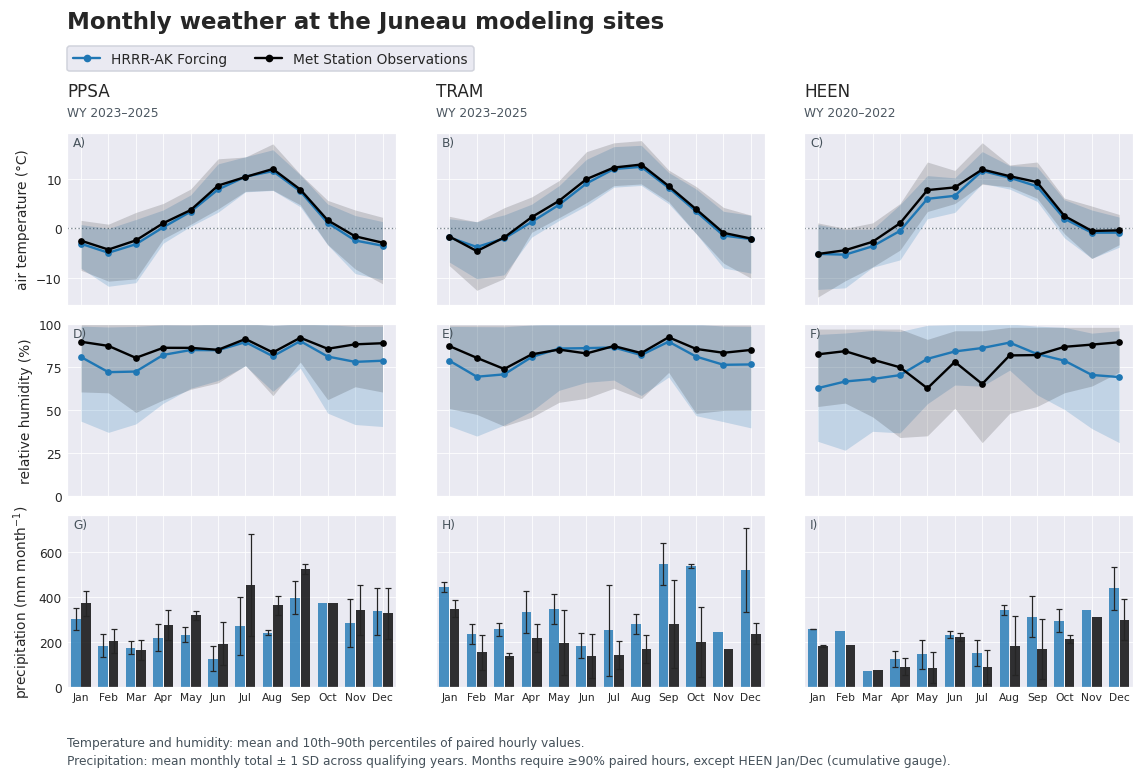

In [4]:
import seaborn as sns

colors = {'HRRR-AK': 'tab:blue', 'Station': 'black'}
legend_labels = {'HRRR-AK': 'HRRR-AK Forcing', 'Station': 'Met Station Observations'}
shade_alpha = {'HRRR-AK': 0.20, 'Station': 0.15}
offsets = {'HRRR-AK': -0.19, 'Station': 0.19}
rows = [('temp', 'air temperature (°C)'), ('rh', 'relative humidity (%)'),
        ('precip', r'precipitation (mm month$^{-1}$)')]

with sns.axes_style('darkgrid'), mpl.rc_context({'font.family': 'DejaVu Sans',
                                                'pdf.fonttype': 42, 'font.size': 9}):
    fig, axes = plt.subplots(3, 3, figsize=(10.8, 7.2), sharex=True, sharey='row')
    fig.subplots_adjust(left=0.086, right=0.983, top=0.82, bottom=0.12,
                        wspace=0.12, hspace=0.11)

    max_precip = 0
    for col, (site, (_, first_wy, last_wy)) in enumerate(sites.items()):
        header = axes[0, col].get_position()
        fig.text(header.x0, 0.867, site, fontsize=11, ha='left')
        fig.text(header.x0, 0.841, f'WY {first_wy}–{last_wy}', fontsize=8,
                 ha='left', color='#4b5660')

        for row, (variable, label) in enumerate(rows):
            ax = axes[row, col]
            ax.set_axisbelow(True)
            ax.grid(color='white', linewidth=0.65, alpha=0.8)
            ax.tick_params(length=0, labelsize=8)
            ax.set_xlim(0.5, 12.5)
            ax.yaxis.set_major_locator(MaxNLocator(4))
            ax.text(0.018, 0.98, f'{chr(65 + row * 3 + col)})', transform=ax.transAxes,
                    ha='left', va='top', fontsize=8, color='#45515a', zorder=5)
            if col == 0:
                ax.set_ylabel(label, fontsize=9)

            if variable == 'temp':
                ax.axhline(0, color='#7b8790', linestyle=':', linewidth=0.9, zorder=1)
            if variable == 'rh':
                ax.set_ylim(0, 100)
                ax.set_yticks([0, 25, 50, 75, 100])

            for source, color in colors.items():
                if variable == 'precip':
                    totals = monthly_precip[site][source]
                    grouped = totals.groupby(totals.index.month)
                    means = grouped.mean().reindex(months)
                    spread = grouped.std(ddof=0).where(grouped.count() >= 2).reindex(months)
                    ax.bar(months + offsets[source], means, width=0.35,
                           color=color, alpha=0.8, linewidth=0, zorder=2)
                    has_spread = spread.notna()
                    ax.errorbar(months[has_spread] + offsets[source], means[has_spread],
                                yerr=spread[has_spread], fmt='none', ecolor='#252525',
                                elinewidth=0.8, capsize=2, capthick=0.8, zorder=3)
                    max_precip = max(max_precip, (means + spread.fillna(0)).max())
                else:
                    mean, low, high = monthly_weather[site][variable]
                    ax.fill_between(months, low[source], high[source], color=color, alpha=shade_alpha[source],
                                    linewidth=0)
                    ax.plot(months, mean[source], color=color, marker='o', markersize=3.4, linewidth=1.55, zorder=3)

        axes[-1, col].set_xticks(months, month_abbr[1:13])
        axes[-1, col].tick_params(axis='x', labelsize=7, pad=3)

    axes[-1, 0].set_ylim(0, max_precip * 1.08)

    fig.text(0.086, 0.975, 'Monthly weather at the Juneau modeling sites',
             ha='left', va='top', fontsize=15, weight='bold')
    legend = [Line2D([], [], color=color, marker='o', markersize=4, linewidth=1.55,
                     label=legend_labels[source]) for source, color in colors.items()]
    fig.legend(handles=legend, loc='upper left', bbox_to_anchor=(0.086, 0.929),
               ncols=2, frameon=True, framealpha=1, facecolor=axes[0, 0].get_facecolor(),
               edgecolor='#d1d3dc', borderaxespad=0, fontsize=9)
    fig.text(0.086, 0.046, 'Temperature and humidity: mean and 10th–90th percentiles of paired hourly values.',
             ha='left', fontsize=8, color='#45515a')
    fig.text(0.086, 0.023, 'Precipitation: mean monthly total ± 1 SD across qualifying years. Months require ≥90% paired hours, except HEEN Jan/Dec (cumulative gauge).',
             ha='left', fontsize=8, color='#45515a')

    output_dir.mkdir(parents=True, exist_ok=True)
    for extension in ('png', 'pdf'):
        fig.savefig(output_dir / f'figure3_publication.{extension}', dpi=300, facecolor='white')
    plt.show()

**HEEN January and December precipitation.** Hourly station coverage was below
90% in all six January and December records (42–89.7%). The cumulative gauge
supports full-month totals for January 2020 and 2021 and December 2019 and 2020.
Each bar averages those two years, using the same full months for HRRR-AK.
December 2021 and January 2022 share a missing month-end gauge reading and were
excluded.